# SVR con y sin reducción de dimensionalidad — Estimador de área cosechada (EVA)

**Inteligencia Artificial I — Grupo C2, 2026-2**

Se compara el **WAPE** del mismo SVR (kernel RBF) en tres versiones. Lo único que cambia es lo que hay entre la preparación de los datos y el SVR:

| Versión | Pipeline | Columnas que recibe el SVR |
|---|---|---|
| Normal | preparación → SVR | ~147 |
| PCA | preparación → **PCA** → SVR | las que se elijan |
| t-SNE | preparación → PCA (50) → **t-SNE** → escalado → SVR | 2 |

Todo lo demás es igual a la fase supervisada: entrenamiento 2007–2021, validación 2022 para elegir, modelo final con 2007–2022 y prueba 2023–2025 **una sola vez**. `C` y `epsilon` quedan fijos (10 y 0,01); solo se ajusta `gamma`, porque depende de las distancias y esas cambian al reducir dimensiones.

| Fase | Qué hace |
|---|---|
| 0–3 | GPU, librerías, limpieza, bloque común y preparación (igual que en `SVR_v3`) |
| A | SVR normal en validación (la referencia) |
| B | PCA: varianza explicada y pruebas manuales de `n_componentes` y `gamma` |
| C | t-SNE (pasos T1–T4): mapa en 2D y pruebas manuales de `perplexity` y `gamma` |
| D | Modelos finales y **prueba** de las 3 versiones |

**GPU:** el SVR y el PCA corren en la GPU con `cuml.accel`. El t-SNE usa la librería `openTSNE`, que corre en **CPU** (no tiene versión para GPU) y es el paso lento.

## 0. Preparación (GPU y librerías)

In [ ]:
# =========================================================
# PASO G0: Activar la aceleracion por GPU (Opcion A)
# =========================================================
# Debe ejecutarse ANTES de importar scikit-learn (primera celda del notebook).
%load_ext cuml.accel
!nvidia-smi -L
print("PASO G0: Ejecutado correctamente")

The cuml.accel extension is already loaded. To reload it, use:
  %reload_ext cuml.accel
GPU 0: Tesla T4 (UUID: GPU-f84e7e20-da9f-e837-6e93-b4acf0c10e9e)
PASO G0: Ejecutado correctamente


In [ ]:
# =========================================================
# Librerias que vamos a usar
# =========================================================

import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.svm import SVR                  # con %load_ext cuml.accel corre en la GPU
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Estilo de las graficas
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["font.size"] = 11

VERDE = "#2a9d8f"
NARANJA = "#e76f51"
AZUL = "#264653"
GRIS = "#bbbbbb"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

print("Librerias cargadas correctamente")

Librerias cargadas correctamente


## 1. Limpieza de datos

In [ ]:
# =====================================================================
# LIMPIEZA DEFINITIVA DE LOS ARCHIVOS EVA (2007-2018 y 2019-2025)
# Resultado: la tabla "datos" con UNA fila por municipio + cultivo +
# estado fisico + anio, lista para entrenar los modelos.
# =====================================================================

import pandas as pd
import numpy as np

# =========================================================
# PASO 1: Cargar los dos archivos desde Google Drive
# =========================================================
print("PASO 1: Cargar los dos archivos desde Google Drive")
# Los archivos deben estar guardados en:  MiUnidad / EVA /
from google.colab import drive
drive.mount("/content/drive")

RUTA = "/content/drive/MyDrive/EVA/"

# Leemos todo como texto: los numeros vienen en formato colombiano
# ("1.247.206,27") y los codigos DANE tienen ceros a la izquierda ("05001").
eva_viejo = pd.read_csv(RUTA + "EVA_2007_2018.csv", dtype=str)
eva_nuevo = pd.read_csv(RUTA + "EVA_2019_2025.csv", dtype=str)

print("EVA 2007-2018:", eva_viejo.shape[0], "filas y", eva_viejo.shape[1], "columnas")
print("EVA 2019-2025:", eva_nuevo.shape[0], "filas y", eva_nuevo.shape[1], "columnas")
print("PASO 1: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 2: Dejar solo las columnas necesarias, con el mismo nombre
# =========================================================
print("PASO 2: Dejar solo las columnas necesarias, con el mismo nombre")

# El archivo viejo trae saltos de linea dentro de los nombres
# ("Área Sembrada\n(ha)"): los cambiamos por un espacio.
eva_viejo.columns = [" ".join(nombre.split()) for nombre in eva_viejo.columns]
eva_nuevo.columns = [" ".join(nombre.split()) for nombre in eva_nuevo.columns]

# Solo columnas que existen en LOS DOS archivos y que se usan despues.
# (El rendimiento no se carga: se recalcula al final con la formula.)
nombres_nuevo = {
    "Código Dane departamento":  "cod_dep",
    "Departamento":              "departamento",
    "Código Dane municipio":     "cod_mun",
    "Municipio":                 "municipio",
    "Grupo cultivo":             "grupo",
    "Cultivo":                   "cultivo",
    "Desagregación cultivo":     "desagregacion",
    "Año":                       "anio",
    "Periodo":                   "periodo",
    "Área sembrada":             "area_sembrada",
    "Área cosechada":            "area_cosechada",
    "Producción":                "produccion",
    "Ciclo del cultivo":         "ciclo",
    "Estado físico del cultivo": "estado_fisico",
}
nombres_viejo = {
    "CÓD. DEP.":                                     "cod_dep",
    "DEPARTAMENTO":                                  "departamento",
    "CÓD. MUN.":                                     "cod_mun",
    "MUNICIPIO":                                     "municipio",
    "GRUPO DE CULTIVO":                              "grupo",
    "CULTIVO":                                       "cultivo",
    "DESAGREGACIÓN REGIONAL Y/O SISTEMA PRODUCTIVO": "desagregacion",
    "AÑO":                                           "anio",
    "PERIODO":                                       "periodo",
    "Área Sembrada (ha)":                            "area_sembrada",
    "Área Cosechada (ha)":                           "area_cosechada",
    "Producción (t)":                                "produccion",
    "CICLO DE CULTIVO":                              "ciclo",
    "ESTADO FISICO PRODUCCION":                      "estado_fisico",
}
COLUMNAS = list(nombres_nuevo.values())
eva_nuevo = eva_nuevo.rename(columns=nombres_nuevo)[COLUMNAS].copy()
eva_viejo = eva_viejo.rename(columns=nombres_viejo)[COLUMNAS].copy()

print("Columnas que se conservan:", COLUMNAS)
print("PASO 2: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 3: Convertir los numeros y los codigos DANE
# =========================================================
print("PASO 3: Convertir los numeros y los codigos DANE")

def convertir_a_numero(columna):
    # "1.247.206,27" -> 1247206.27  (el punto separa miles, la coma es decimal)
    texto = columna.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    return pd.to_numeric(texto, errors="coerce")

for df in (eva_viejo, eva_nuevo):
    for columna in ["anio", "area_sembrada", "area_cosechada", "produccion"]:
        df[columna] = convertir_a_numero(df[columna])
    df["anio"] = df["anio"].astype(int)
    # Codigos: "15.114" -> "15114"  y  "5.001" -> "05001"
    df["cod_dep"] = df["cod_dep"].str.replace(".", "", regex=False).str.zfill(2)
    df["cod_mun"] = df["cod_mun"].str.replace(".", "", regex=False).str.zfill(5)

# Controles: ningun numero vacio, ningun negativo, codigos coherentes
for nombre, df in [("2007-2018", eva_viejo), ("2019-2025", eva_nuevo)]:
    numeros = df[["area_sembrada", "area_cosechada", "produccion"]]
    assert numeros.notna().all().all(), "Hay numeros que no se pudieron convertir en " + nombre
    assert (numeros >= 0).all().all(), "Hay numeros negativos en " + nombre
    assert (df["cod_mun"].str[:2] == df["cod_dep"]).all(), "Codigos inconsistentes en " + nombre

print("PASO 3: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 4: Poner el texto en mayusculas y sin tildes
# =========================================================
print("PASO 4: Poner el texto en mayusculas y sin tildes")

def limpiar_texto(columna):
    texto = columna.str.upper().str.strip()
    texto = texto.str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("utf-8")
    return texto.str.replace(r"\s+", " ", regex=True)   # espacios dobles -> uno

for df in (eva_viejo, eva_nuevo):
    for columna in ["departamento", "municipio", "grupo", "cultivo",
                    "desagregacion", "ciclo", "estado_fisico"]:
        df[columna] = limpiar_texto(df[columna])

print("PASO 4: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 5: Estandarizar los nombres de cultivo y de estado fisico
# =========================================================
# Regla: solo se unifica lo que es el MISMO cultivo. Lo que es distinto
# se deja separado, y si queda solo en un archivo se elimina en el PASO 6.
print("PASO 5: Estandarizar los nombres de cultivo y de estado fisico")

# 5.1 El archivo nuevo junta las tres canas en "CANA", pero la desagregacion
#     las separa. Como son productos distintos, las separamos igual que el viejo.
es_cana = eva_nuevo["cultivo"] == "CANA"
eva_nuevo.loc[es_cana, "cultivo"] = eva_nuevo.loc[es_cana, "desagregacion"]
eva_nuevo["cultivo"] = eva_nuevo["cultivo"].replace({"CANA DE AZUCAR": "CANA AZUCARERA",
                                                     "ESTEVIA": "STEVIA"})

# 5.2 Nombres del archivo viejo que se pasan al nombre del archivo nuevo.
cultivos_equivalentes = {
    # a) El mismo cultivo, solo cambio el nombre
    "DURAZNO":     "DURAZNO O ALBARICOQUE",
    "AGRAZ":       "AGRAZ - MORTINO",
    "PEPA DE PAN": "ARBOL DE PAN O PEPA DEL PAN",
    "PAPAYUELA":   "PAPAYUELA -BABACO",
    "CURCUMA":     "CURCUMA O AZAFRAN",
    "RUBA":        "ULLUCO",
    # b) El archivo nuevo definio una categoria que junta exactamente
    #    los cultivos que el viejo traia separados
    "GULUPA":      "GULUPA O CHOLUPA",
    "CHOLUPA":     "GULUPA O CHOLUPA",
    "CALABACIN":   "CALABACIN, CALABAZA",
    "CALABAZA":    "CALABACIN, CALABAZA",
    "MALANGA":     "MALANGA, ACHIN, YOTA, PAPA CHINA, BORE",
    "BORE":        "MALANGA, ACHIN, YOTA, PAPA CHINA, BORE",
}
eva_viejo["cultivo"] = eva_viejo["cultivo"].replace(cultivos_equivalentes)

# 5.3 Estado fisico: se unifican solo los nombres que significan lo mismo.
#     Lo demas se deja como viene (ej. PANELA y CANA O VERDE son distintos).
estados_equivalentes = {
    "FRUTO FRESCO":       "EN FRESCO",
    "HORTALIZA FRESCA":   "EN FRESCO",
    "TUBERCULO FRESCO":   "EN FRESCO",
    "HOJA FRESCA":        "EN FRESCO",
    "LEGUMINOSA FRESCA":  "EN FRESCO",
    "PADDY VERDE":        "PADDY O CASCARA VERDE",
    "SEMILLA":            "ALGODON SEMILLA",
    "CANA PARA MOLIENDA": "CANA O VERDE",
}
eva_viejo["estado_fisico"] = eva_viejo["estado_fisico"].replace(estados_equivalentes)

print("PASO 5: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos
# =========================================================
print("PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos")

# 6.1 Nos quedamos solo con los cultivos que aparecen en LOS DOS archivos
cultivos_comunes = set(eva_viejo["cultivo"]) & set(eva_nuevo["cultivo"])
eliminados = (pd.concat([eva_viejo, eva_nuevo])
                .loc[lambda df: ~df["cultivo"].isin(cultivos_comunes)]
                .groupby("cultivo")["area_cosechada"].sum()
                .sort_values(ascending=False))
print("Cultivos que estan en un solo archivo (se eliminan):", len(eliminados))
print("Los 10 con mas area cosechada:")
print(eliminados.head(10).round(0))

eva_viejo = eva_viejo[eva_viejo["cultivo"].isin(cultivos_comunes)].copy()
eva_nuevo = eva_nuevo[eva_nuevo["cultivo"].isin(cultivos_comunes)].copy()

# 6.2 Catalogo: grupo y ciclo de cada cultivo segun el archivo nuevo
#     (ahi cada cultivo tiene un solo grupo y un solo ciclo)
catalogo = eva_nuevo.groupby("cultivo")[["grupo", "ciclo"]].first()
assert (eva_nuevo.groupby("cultivo")["grupo"].nunique() == 1).all()
assert (eva_nuevo.groupby("cultivo")["ciclo"].nunique() == 1).all()

# 6.3 El archivo viejo toma el grupo y el ciclo del catalogo
eva_viejo["grupo"] = eva_viejo["cultivo"].map(catalogo["grupo"])
eva_viejo["ciclo"] = eva_viejo["cultivo"].map(catalogo["ciclo"])

print("Cultivos que quedan:", len(cultivos_comunes))
print("Grupos:", sorted(catalogo["grupo"].unique()))
print("PASO 6: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 7: Unir los dos archivos y quitar los anios 2006 y 2018
# =========================================================
print("PASO 7: Unir los dos archivos y quitar los anios 2006 y 2018")

eva_viejo["fuente"] = "2007-2018"
eva_nuevo["fuente"] = "2019-2025"
datos = pd.concat([eva_viejo, eva_nuevo], ignore_index=True)

# Nombres oficiales a partir del codigo DANE (se usa el del archivo nuevo).
# Asi un municipio no aparece con dos nombres ("DON MATIAS" / "DONMATIAS").
for codigo, nombre in [("cod_dep", "departamento"), ("cod_mun", "municipio")]:
    nombre_oficial = datos.sort_values("fuente").groupby(codigo)[nombre].last()
    datos[nombre] = datos[codigo].map(nombre_oficial)

# 2006: solo trae el semestre B.  2018: no trae el semestre B.
# Los dos anios estan incompletos y sesgarian los totales anuales.
print("Filas del 2006:", (datos["anio"] == 2006).sum())
print("Filas del 2018:", (datos["anio"] == 2018).sum())
datos = datos[~datos["anio"].isin([2006, 2018])]

print("Filas despues de unir:", len(datos))
print("PASO 7: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 8: Pasar de semestres a anios (suma simple)
# =========================================================
# Se suman los semestres A y B y las variedades (desagregaciones) de cada
# cultivo. La produccion solo se suma entre filas con el MISMO estado fisico,
# por eso el estado fisico es parte de la clave (ej. maiz en grano seco y
# maiz en fresco quedan en filas separadas).
print("PASO 8: Pasar de semestres a anios (suma simple)")

CLAVE = ["cod_mun", "cultivo", "estado_fisico", "anio"]
datos = (datos.groupby(CLAVE, as_index=False)
              .agg(fuente=("fuente", "first"),
                   cod_dep=("cod_dep", "first"),
                   departamento=("departamento", "first"),
                   municipio=("municipio", "first"),
                   grupo=("grupo", "first"),
                   ciclo=("ciclo", "first"),
                   area_sembrada=("area_sembrada", "sum"),
                   area_cosechada=("area_cosechada", "sum"),
                   produccion=("produccion", "sum")))

# Rendimiento recalculado con la formula (vacio si no hubo cosecha)
datos["rendimiento"] = np.where(datos["area_cosechada"] > 0,
                                datos["produccion"] / datos["area_cosechada"], np.nan)

print("Filas anuales:", len(datos))
print("PASO 8: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 9: Regla de arrastre (sin tolerancia) y consistencia
# =========================================================
# En los cultivos TRANSITORIOS, lo sembrado y no cosechado un anio puede
# cosecharse al anio siguiente (solo se arrastra UN anio):
#     area_pendiente_anterior = sembrada(anio-1) - cosechada(anio-1)   (si es > 0)
#     area_disponible         = sembrada(anio) + area_pendiente_anterior
# En los PERMANENTES no hay arrastre (el area sembrada ya es todo lo plantado).
# Se elimina toda fila que coseche mas que el area disponible.
print("PASO 9: Regla de arrastre (sin tolerancia) y consistencia")

datos = datos.sort_values(CLAVE).reset_index(drop=True)
serie = datos.groupby(["cod_mun", "cultivo", "estado_fisico"])
sembrada_ant = serie["area_sembrada"].shift(1)
cosechada_ant = serie["area_cosechada"].shift(1)
anio_ant = serie["anio"].shift(1)

# Solo hay arrastre si existe el anio inmediatamente anterior y es transitorio
hay_arrastre = (datos["anio"] - anio_ant == 1) & (datos["ciclo"] == "TRANSITORIO")
datos["area_pendiente_anterior"] = np.where(hay_arrastre,
                                            (sembrada_ant - cosechada_ant).clip(lower=0), 0.0)
area_disponible = datos["area_sembrada"] + datos["area_pendiente_anterior"]

regla_arrastre = datos["area_cosechada"] > area_disponible        # cosecho mas de lo disponible
regla_produccion = (datos["produccion"] > 0) & (datos["area_cosechada"] == 0)   # produccion sin cosecha
sin_area = area_disponible == 0                                    # nada sembrado ni pendiente

print("Cosecharon mas que el area disponible:", regla_arrastre.sum())
print("Produccion sin area cosechada        :", regla_produccion.sum())
print("Sin area sembrada ni pendiente       :", sin_area.sum())
datos = datos[~(regla_arrastre | regla_produccion | sin_area)].reset_index(drop=True)

print("Filas que quedan:", len(datos))
print("PASO 9: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 10: Agregar la altura de cada municipio (msnm)
# =========================================================
# Fuente: IGAC, publicada en el Panel Municipal del CEDE (Universidad de los
# Andes), archivo "PANEL_CARACTERISTICAS_GENERALES_2021.csv" guardado en la
# misma carpeta de Drive. Columnas usadas: codmpio (codigo DANE) y altura (msnm).
print("PASO 10: Agregar la altura de cada municipio (msnm)")

ARCHIVO_ALTURA = RUTA + "PANEL_CARACTERISTICAS_GENERALES_2021.csv"
altura = pd.read_csv(ARCHIVO_ALTURA, usecols=["codmpio", "altura"], encoding="latin-1")

# El panel trae una fila por anio, pero la altura de un municipio no cambia:
# nos quedamos con una sola fila por municipio.
altura = altura.dropna(subset=["altura"]).drop_duplicates(subset="codmpio")
altura["cod_mun"] = altura["codmpio"].astype(int).astype(str).str.zfill(5)   # 5001 -> "05001"
altura = altura.rename(columns={"altura": "altura_msnm"})[["cod_mun", "altura_msnm"]]

# Municipios que no estan en el panel (creados despues): altura aproximada a mano
altura_manual = pd.DataFrame({
    "cod_mun":     ["27493"],     # NUEVO BELEN DE BAJIRA (Choco)
    "altura_msnm": [105],
})
altura = pd.concat([altura, altura_manual], ignore_index=True)

datos = datos.merge(altura, on="cod_mun", how="left")

print("PASO 10: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 11: Revision final y orden de columnas
# =========================================================
print("PASO 11: Revision final y orden de columnas")

# La clave debe ser unica: una fila por municipio + cultivo + estado + anio
assert not datos.duplicated(CLAVE).any(), "Hay filas repetidas en la clave"

COLUMNAS_FINALES = ["anio", "fuente", "cod_dep", "departamento", "cod_mun", "municipio",
                    "altura_msnm", "grupo", "cultivo", "ciclo", "estado_fisico",
                    "area_sembrada", "area_pendiente_anterior", "area_cosechada",
                    "produccion", "rendimiento"]
datos = datos[COLUMNAS_FINALES]

print("Filas:", len(datos), "| Columnas:", datos.shape[1])
print("Anios:", sorted(datos["anio"].unique()))
print("Departamentos:", datos["cod_dep"].nunique(), "| Municipios:", datos["cod_mun"].nunique(),
      "| Cultivos:", datos["cultivo"].nunique(), "| Grupos:", datos["grupo"].nunique())
print()
print("Datos faltantes por columna:")
print(datos.isna().sum()[datos.isna().sum() > 0])
print("(el rendimiento queda vacio solo cuando el area cosechada es 0)")
print()
print("Filas por grupo y archivo:")
print(pd.crosstab(datos["grupo"], datos["fuente"]))
print()
# Cultivos cuyo estado fisico cambia entre archivos (su produccion no se compara)
estados = datos.groupby(["cultivo", "fuente"])["estado_fisico"].apply(lambda s: " / ".join(sorted(s.unique())))
estados = estados.unstack()
cambian = estados[estados["2007-2018"] != estados["2019-2025"]]
print("Cultivos cuyo estado fisico cambia entre archivos:", len(cambian))
print(cambian)
print("PASO 11: Ejecutado correctamente")
print("-------------------------------")

# Para guardar (al leerlo de nuevo, usar dtype={"cod_dep": str, "cod_mun": str}):
# datos.to_csv(RUTA + "eva_limpio.csv", index=False, encoding="utf-8-sig")

datos.head()

PASO 1: Cargar los dos archivos desde Google Drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EVA 2007-2018: 206068 filas y 17 columnas
EVA 2019-2025: 166732 filas y 18 columnas
PASO 1: Ejecutado correctamente
-------------------------------
PASO 2: Dejar solo las columnas necesarias, con el mismo nombre
Columnas que se conservan: ['cod_dep', 'departamento', 'cod_mun', 'municipio', 'grupo', 'cultivo', 'desagregacion', 'anio', 'periodo', 'area_sembrada', 'area_cosechada', 'produccion', 'ciclo', 'estado_fisico']
PASO 2: Ejecutado correctamente
-------------------------------
PASO 3: Convertir los numeros y los codigos DANE
PASO 3: Ejecutado correctamente
-------------------------------
PASO 4: Poner el texto en mayusculas y sin tildes
PASO 4: Ejecutado correctamente
-------------------------------
PASO 5: Estandarizar los nombres de cultivo y de estado fisico
PASO 5: Ejecutado correctamente
------------

,anio,fuente,cod_dep,departamento,cod_mun,municipio,altura_msnm,grupo,cultivo,ciclo,estado_fisico,area_sembrada,area_pendiente_anterior,area_cosechada,produccion,rendimiento
0,2007,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.000",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,10.000,0.000,0.000,0.000,NaN
1,2008,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.000",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,10.000,0.000,0.000,0.000,NaN
2,2009,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.000",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,12.000,0.000,6.000,36.000,6.000
3,2010,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.000",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,16.000,0.000,10.000,60.000,6.000
4,2011,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.000",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,19.000,0.000,16.000,96.000,6.000


## 2. Bloque común (features, división por años y métricas)

In [ ]:
# =========================================================
# PASO C1: Construir las features
# =========================================================
# Todas salen de columnas de la tabla limpia. Cada serie es un
# municipio + cultivo + estado fisico a lo largo de los anios.
print("PASO C1: Construir las features")

# --- Valores fijos del proyecto (iguales para los 4 modelos) ---
SEMILLA = 42
ANIO_FIN_ENTRENO = 2021              # entrenamiento: 2007-2021 (sin 2018)
ANIO_VALIDACION = 2022               # validacion: elegir hiperparametros
ANIOS_PRUEBA = [2023, 2024, 2025]    # prueba: se evalua UNA sola vez al final

SERIE = ["cod_mun", "cultivo", "estado_fisico"]
df = datos.sort_values(SERIE + ["anio"]).reset_index(drop=True)

# Area que habia para cosechar (sembrada + pendiente del anio anterior)
df["area_disponible"] = df["area_sembrada"] + df["area_pendiente_anterior"]

# Datos del anio anterior de la misma serie (0 si no existe ese anio)
serie = df.groupby(SERIE)
anio_ant = serie["anio"].shift(1)
df["hay_ant"] = ((df["anio"] - anio_ant) == 1).astype(int)
df["cosechada_ant"] = np.where(df["hay_ant"] == 1, serie["area_cosechada"].shift(1), 0)
df["sembrada_ant"] = np.where(df["hay_ant"] == 1, serie["area_sembrada"].shift(1), 0)

# Tasa historica: promedio de (cosechada / disponible) en los anios ANTERIORES de la serie
df["tasa_real"] = df["area_cosechada"] / df["area_disponible"]
df["tasa_hist"] = serie["tasa_real"].transform(lambda s: s.shift(1).expanding().mean())
df["hay_hist"] = df["tasa_hist"].notna().astype(int)

# Columnas de texto pasadas a 0/1
df["permanente"] = (df["ciclo"] == "PERMANENTE").astype(int)
df["rep2019"] = (df["fuente"] == "2019-2025").astype(int)

# Logaritmos: las areas van de menos de 1 ha a mas de 100.000 ha
for col in ["area_sembrada", "area_disponible", "cosechada_ant", "sembrada_ant"]:
    df["log_" + col] = np.log1p(df[col])

print("Filas:", len(df))
print("PASO C1: Ejecutado correctamente")
print("-------------------------------")

PASO C1: Construir las features
Filas: 238350
PASO C1: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO C2: Division por anios (nunca al azar)
# =========================================================
print("PASO C2: Division por anios")
entreno = df[df["anio"] <= ANIO_FIN_ENTRENO].copy()
validacion = df[df["anio"] == ANIO_VALIDACION].copy()
prueba = df[df["anio"].isin(ANIOS_PRUEBA)].copy()

print("Entrenamiento (2007-2021):", len(entreno))
print("Validacion (2022)        :", len(validacion))
print("Prueba (2023-2025)       :", len(prueba))
print("PASO C2: Ejecutado correctamente")
print("-------------------------------")

PASO C2: Division por anios
Entrenamiento (2007-2021): 176975
Validacion (2022)        : 15041
Prueba (2023-2025)       : 46334
PASO C2: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO C3: Funciones de evaluacion (iguales para los 4 modelos)
# =========================================================
print("PASO C3: Funciones de evaluacion")

def objetivo(tabla):
    return np.log1p(tabla["area_cosechada"].values)          # el modelo aprende log(1 + area)

def a_hectareas(pred_log, tabla):
    # Volver a hectareas y no pasar del area disponible
    return np.clip(np.expm1(pred_log), 0, tabla["area_disponible"].values)

def metricas(real, estimada):
    """Las 5 metricas del proyecto (en hectareas)."""
    mse = mean_squared_error(real, estimada)
    return {"MSE": mse,
            "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(real, estimada),
            "WAPE_%": np.abs(real - estimada).sum() / real.sum() * 100,
            "R2": r2_score(real, estimada)}

def tabla_resultados(tabla, estimada, nombre_modelo):
    """Metricas del modelo y de las 2 reglas base, total y por grupo."""
    reglas = {nombre_modelo: estimada,
              "Base: cosechada = sembrada": tabla["area_sembrada"].values,
              "Base: disponible x tasa historica": (tabla["area_disponible"] * tabla["tasa_hist"]).values}
    real = tabla["area_cosechada"].values
    filas = []
    for nombre, est in reglas.items():
        filas.append({"modelo": nombre, "grupo": "TOTAL", **metricas(real, est)})
        for g in sorted(tabla["grupo"].unique()):
            m = (tabla["grupo"] == g).values
            filas.append({"modelo": nombre, "grupo": g, **metricas(real[m], est[m])})
    return pd.DataFrame(filas)

def tabla_predicciones(tabla, estimada, nombre_modelo):
    """Predicciones en el formato comun del equipo, con la tasa de cosecha efectiva."""
    salida = tabla[["anio", "cod_mun", "municipio", "departamento", "grupo", "cultivo",
                    "estado_fisico", "area_sembrada", "area_disponible", "area_cosechada"]].copy()
    salida["area_cosechada_estimada"] = estimada
    sembrada = salida["area_sembrada"].replace(0, np.nan)
    salida["tasa_cosecha_real_%"] = salida["area_cosechada"] / sembrada * 100
    salida["tasa_cosecha_estimada_%"] = salida["area_cosechada_estimada"] / sembrada * 100
    salida["modelo"] = nombre_modelo
    return salida

print("PASO C3: Ejecutado correctamente")
print("-------------------------------")

PASO C3: Funciones de evaluacion
PASO C3: Ejecutado correctamente
-------------------------------


## 3. Preparación de los datos y piezas del pipeline

Igual que en `SVR_v3`: continuas con `StandardScaler`, binarias en 0/1 y categóricas en one-hot. Aquí la preparación y el SVR quedan como **piezas separadas**, para poder poner PCA o t-SNE en medio.

In [ ]:
# =========================================================
# PASO M1: Preparar los datos y definir las piezas del pipeline
# =========================================================
print("PASO M1: Preparar los datos y definir las piezas del pipeline")
SEMILLA = 42
C_FIJO = 10              # elegidos en la fase supervisada; aqui no se cambian
EPSILON_FIJO = 0.01
GAMMA_NORMAL = 0.01      # gamma del SVR normal (elegido en la fase supervisada)

def preparar(tabla_entreno, tabla, ultimo_anio):
    """Prepara 'tabla' usando solo informacion de 'tabla_entreno'."""
    t = tabla.copy()
    # 1) tasa_hist vacia -> promedio del cultivo en entrenamiento (o promedio general)
    tasa_cultivo = tabla_entreno.groupby("cultivo")["tasa_real"].mean()
    t["tasa_hist"] = t["tasa_hist"].fillna(t["cultivo"].map(tasa_cultivo))
    t["tasa_hist"] = t["tasa_hist"].fillna(tabla_entreno["tasa_real"].mean())
    # 2) Cultivos con menos de 100 filas de entrenamiento -> "OTROS"
    conteo = tabla_entreno["cultivo"].value_counts()
    cultivos_ok = conteo[conteo >= 100].index
    t["cultivo_mod"] = np.where(t["cultivo"].isin(cultivos_ok), t["cultivo"], "OTROS")
    # 3) Anio topado al ultimo anio de entrenamiento
    t["anio_mod"] = t["anio"].clip(upper=ultimo_anio)
    return t

ent = preparar(entreno, entreno, ANIO_FIN_ENTRENO)
val = preparar(entreno, validacion, ANIO_FIN_ENTRENO)

CONTINUAS = ["log_area_sembrada", "log_area_disponible", "log_cosechada_ant",
             "log_sembrada_ant", "tasa_hist", "altura_msnm", "anio_mod"]   # -> StandardScaler
BINARIAS = ["hay_ant", "hay_hist", "rep2019", "permanente"]               # -> se quedan en 0/1
CATEGORIAS = ["grupo", "cultivo_mod", "cod_dep"]                          # -> one-hot 0/1

def crear_preparacion():
    """Pieza 1: escalado y one-hot (aprenden SOLO de los datos con que se entrena)."""
    return ColumnTransformer([
        ("continuas", StandardScaler(), CONTINUAS),
        ("binarias", "passthrough", BINARIAS),
        ("categorias", OneHotEncoder(drop="first", handle_unknown="ignore"), CATEGORIAS),
    ], sparse_threshold=0)

def a_float32():
    return FunctionTransformer(lambda X: np.asarray(X).astype(np.float32))   # mas rapido en GPU

def crear_svr(gamma):
    """Pieza final: el mismo SVR de la fase supervisada; solo cambia gamma."""
    return SVR(kernel="rbf", C=C_FIJO, gamma=gamma, epsilon=EPSILON_FIJO, cache_size=1000)

def wape(real, estimada):
    return np.abs(real - estimada).sum() / real.sum() * 100

# Referencia: la regla "cosechada = sembrada" en validacion
WAPE_REGLA_VAL = wape(val["area_cosechada"].values, val["area_sembrada"].values.astype(float))

N_COLUMNAS = crear_preparacion().fit_transform(ent).shape[1]
print("Filas de entrenamiento:", len(ent), "| Filas de validacion:", len(val))
print("Columnas despues de la preparacion:", N_COLUMNAS)
print("PASO M1: Ejecutado correctamente")
print("-------------------------------")

PASO M1: Preparar los datos y definir las piezas del pipeline
Filas de entrenamiento: 176975 | Filas de validacion: 15041
Columnas despues de la preparacion: 147
PASO M1: Ejecutado correctamente
-------------------------------


## Fase A — SVR normal (referencia)

El SVR de la fase supervisada, sin reducción, medido en validación (2022). Es la línea contra la que se comparan PCA y t-SNE. También se cargan el registro de corridas y las funciones de las gráficas.

In [ ]:
# =========================================================
# PASO A1: SVR normal en validacion y registro de corridas
# =========================================================
print("PASO A1: SVR normal en validacion")
RUTA_REDUCCION = RUTA + "Resultados_reduccion/"
os.makedirs(RUTA_REDUCCION, exist_ok=True)
ARCHIVO_REGISTRO = RUTA_REDUCCION + "corridas_reduccion.csv"

REINICIAR_REGISTRO = False     # True = borra todas las corridas guardadas (usar una sola vez)

inicio = time.time()
modelo_normal = Pipeline([("preparacion", crear_preparacion()), ("float32", a_float32()),
                          ("svr", crear_svr(GAMMA_NORMAL))])
modelo_normal.fit(ent, objetivo(ent))
WAPE_NORMAL_ENT = wape(ent["area_cosechada"].values, a_hectareas(modelo_normal.predict(ent), ent))
WAPE_NORMAL_VAL = wape(val["area_cosechada"].values, a_hectareas(modelo_normal.predict(val), val))
print("SVR normal (" + str(N_COLUMNAS) + " columnas, gamma = " + str(GAMMA_NORMAL) + ") |",
      round(time.time() - inicio), "s")
print("WAPE entrenamiento:", round(WAPE_NORMAL_ENT, 2), "% | WAPE validacion:", round(WAPE_NORMAL_VAL, 2),
      "% | regla simple:", round(WAPE_REGLA_VAL, 2), "%")

# Registro de corridas de PCA y t-SNE (se guarda en Drive y no se pierde al reiniciar)
if os.path.exists(ARCHIVO_REGISTRO) and not REINICIAR_REGISTRO:
    registro = pd.read_csv(ARCHIVO_REGISTRO)
else:
    registro = pd.DataFrame(columns=["version", "parametro", "gamma", "WAPE_entreno", "WAPE_validacion", "segundos"])
print("Corridas guardadas:", len(registro))

def txt(v):
    """Numero sin ceros sobrantes: 30.0 -> '30', 0.0030 -> '0.003'."""
    return "{:g}".format(v)

def agregar_corrida(version, parametro, gamma, wape_ent, wape_val, segundos):
    """Agrega una corrida al registro y lo guarda en Drive."""
    global registro
    fila = pd.DataFrame([{"version": version, "parametro": parametro, "gamma": gamma, "WAPE_entreno": wape_ent,
                          "WAPE_validacion": wape_val, "segundos": segundos}])
    registro = fila if len(registro) == 0 else pd.concat([registro, fila], ignore_index=True)
    # Columnas numericas como numeros (si no, las graficas fallan)
    numericas = ["parametro", "gamma", "WAPE_entreno", "WAPE_validacion", "segundos"]
    registro[numericas] = registro[numericas].astype(float)
    registro.to_csv(ARCHIVO_REGISTRO, index=False)

def graficar_corridas(version, nombre_parametro):
    """Dos paneles: WAPE segun el parametro de la reduccion (gamma fijo) y segun gamma (parametro fijo)."""
    tabla = registro[registro["version"] == version]
    actual = tabla.iloc[-1]
    figura, ejes = plt.subplots(1, 2, figsize=(15, 5))
    for ax, columna, fija, nombre in [(ejes[0], "parametro", "gamma", nombre_parametro),
                                      (ejes[1], "gamma", "parametro", "gamma")]:
        nombre_fija = "gamma" if fija == "gamma" else nombre_parametro
        t = tabla[np.isclose(tabla[fija].astype(float), float(actual[fija]))]
        t = t.groupby(columna, as_index=False)[["WAPE_entreno", "WAPE_validacion"]].mean()
        ax.plot(t[columna], t["WAPE_entreno"], marker="o", color=VERDE, label="Entrenamiento")
        ax.plot(t[columna], t["WAPE_validacion"], marker="o", color=NARANJA, label="Validacion (2022)")
        ax.axhline(WAPE_NORMAL_VAL, color=AZUL, linestyle="--", label="SVR normal (validacion)")
        ax.axhline(WAPE_REGLA_VAL, color="gray", linestyle=":", label="Regla cosechada = sembrada")
        ax.axvline(actual[columna], color="gray", alpha=0.4, label="Valor actual")
        if columna == "gamma" and len(t) > 1:
            ax.set_xscale("log")
            ax.minorticks_off()
        ax.set_xticks(t[columna])
        ax.set_xticklabels([txt(v) for v in t[columna]])
        ax.set_xlabel(nombre)
        ax.set_ylabel("WAPE (%)")
        ax.set_title(version + ": WAPE segun " + nombre + " (" + nombre_fija + " = " + txt(actual[fija]) + ")")
    marcas, nombres = ejes[0].get_legend_handles_labels()
    figura.legend(marcas, nombres, frameon=False, loc="lower center", ncol=5, fontsize=9)
    plt.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()

print("PASO A1: Ejecutado correctamente")
print("-------------------------------")

PASO A1: SVR normal en validacion
SVR normal (147 columnas, gamma = 0.01) | 64 s
WAPE entrenamiento: 8.18 % | WAPE validacion: 7.2 % | regla simple: 9.99 %
Corridas guardadas: 5
PASO A1: Ejecutado correctamente
-------------------------------


## Fase B — SVR con PCA

PCA resume las columnas en **componentes**: combinaciones de las columnas originales, ordenadas de la que más varianza conserva a la que menos.

**B1 — Gráfica de varianza explicada:** cuánta información (varianza) se conserva según el número de componentes. Sirve para escoger qué valores de `n_componentes` vale la pena probar.

**B2 y B3 — Pruebas manuales:** escribir `N_COMPONENTES` y `GAMMA_PCA` en **B2** y ejecutar **B2 y B3**. Cada corrida se agrega a las gráficas:
- izquierda: WAPE según `n_componentes` (con el gamma actual);
- derecha: WAPE según `gamma` (con el n_componentes actual).

Se busca el valor con el **WAPE de validación más bajo**; la línea azul es el SVR normal.

PASO B1: Varianza explicada por el PCA


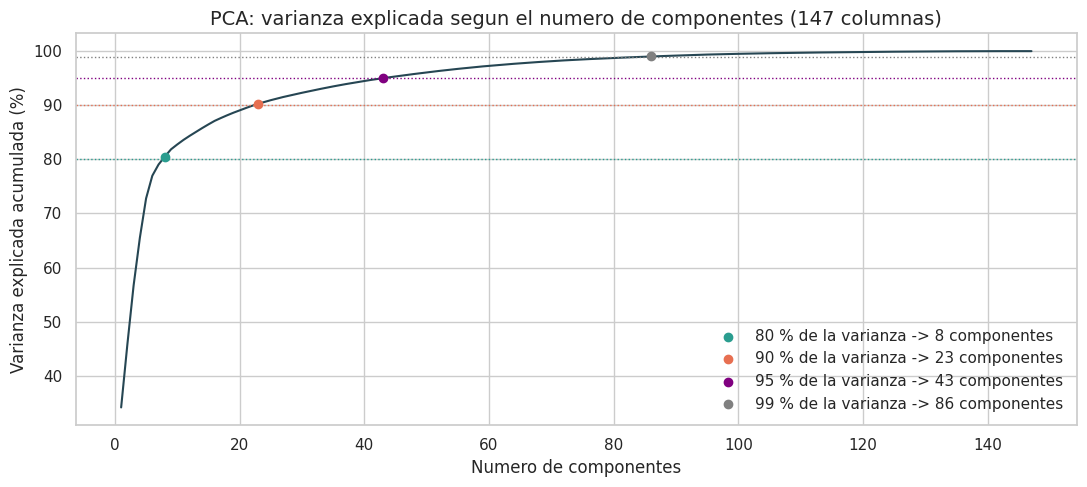

Varianza de las primeras 10 componentes (%): [34.2 11.7 10.9  8.8  7.3  4.2  2.1  1.5  1.4  0.9]
PASO B1: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO B1: Varianza explicada por el PCA
# =========================================================
print("PASO B1: Varianza explicada por el PCA")
X_ent = crear_preparacion().fit_transform(ent)
pca_completo = PCA(random_state=SEMILLA).fit(X_ent)
acumulada = np.cumsum(np.asarray(pca_completo.explained_variance_ratio_)) * 100

plt.figure(figsize=(11, 5))
plt.plot(range(1, len(acumulada) + 1), acumulada, color=AZUL)
for porcentaje, color in [(80, VERDE), (90, NARANJA), (95, "purple"), (99, "gray")]:
    n = int(np.argmax(acumulada >= porcentaje)) + 1
    plt.axhline(porcentaje, color=color, linestyle=":", linewidth=1)
    plt.scatter([n], [acumulada[n - 1]], color=color, zorder=5,
                label=str(porcentaje) + " % de la varianza -> " + str(n) + " componentes")
plt.xlabel("Numero de componentes")
plt.ylabel("Varianza explicada acumulada (%)")
plt.title("PCA: varianza explicada segun el numero de componentes (" + str(len(acumulada)) + " columnas)")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

print("Varianza de las primeras 10 componentes (%):", np.round(np.asarray(pca_completo.explained_variance_ratio_)[:10] * 100, 1))
print("PASO B1: Ejecutado correctamente")
print("-------------------------------")

In [ ]:
# =========================================================
# PASO B2: Parametros de la corrida con PCA  (EDITAR AQUI)
# =========================================================
print("PASO B2: Parametros de la corrida con PCA")

N_COMPONENTES = 86      # numero de componentes del PCA (ver la grafica de B1)
GAMMA_PCA = 0.01        # gamma del SVR

print("n_componentes =", N_COMPONENTES, "| gamma =", GAMMA_PCA)
print("PASO B2: Ejecutado correctamente")
print("-------------------------------")

PASO B2: Parametros de la corrida con PCA
n_componentes = 86 | gamma = 0.01
PASO B2: Ejecutado correctamente
-------------------------------


PASO B3: Correr el SVR con PCA
PCA con 86 componentes ( 99.0 % de la varianza ) | gamma = 0.01
WAPE entrenamiento: 8.3 % | WAPE validacion: 7.36 % | SVR normal: 7.2 % | 57 s


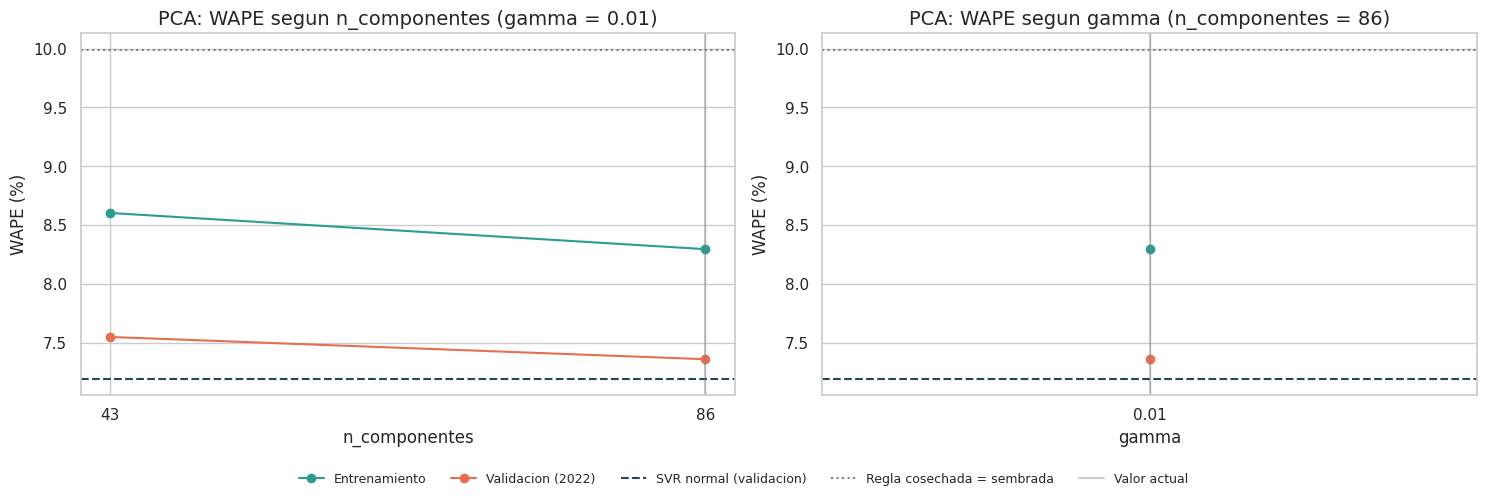

version  n_componentes  gamma  WAPE_entreno  WAPE_validacion  segundos
    PCA         43.000  0.010         8.603            7.549    46.000
    PCA         43.000  0.010         8.603            7.549    44.000
    PCA         43.000  0.100         6.963            7.753   493.000
    PCA         43.000  0.001         9.835            8.201    26.000
    PCA         86.000  0.010         8.295            7.360    57.000
    PCA         86.000  0.010         8.295            7.360    57.000
PASO B3: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO B3: Correr el SVR con PCA y agregarlo a las graficas
# =========================================================
print("PASO B3: Correr el SVR con PCA")

def crear_modelo_pca(n_componentes, gamma):
    return Pipeline([("preparacion", crear_preparacion()),
                     ("pca", PCA(n_components=n_componentes, random_state=SEMILLA)),
                     ("float32", a_float32()),
                     ("svr", crear_svr(gamma))])

inicio = time.time()
modelo_pca = crear_modelo_pca(N_COMPONENTES, GAMMA_PCA)
modelo_pca.fit(ent, objetivo(ent))
wape_ent = wape(ent["area_cosechada"].values, a_hectareas(modelo_pca.predict(ent), ent))
wape_val = wape(val["area_cosechada"].values, a_hectareas(modelo_pca.predict(val), val))
segundos = round(time.time() - inicio)
agregar_corrida("PCA", N_COMPONENTES, GAMMA_PCA, wape_ent, wape_val, segundos)

print("PCA con", N_COMPONENTES, "componentes (", round(acumulada[N_COMPONENTES - 1], 1), "% de la varianza ) | gamma =", GAMMA_PCA)
print("WAPE entrenamiento:", round(wape_ent, 2), "% | WAPE validacion:", round(wape_val, 2),
      "% | SVR normal:", round(WAPE_NORMAL_VAL, 2), "% |", segundos, "s")

graficar_corridas("PCA", "n_componentes")
print(registro[registro["version"] == "PCA"].rename(columns={"parametro": "n_componentes"}).round(3).to_string(index=False))
print("PASO B3: Ejecutado correctamente")
print("-------------------------------")

## Fase C — Mapas t-SNE (solo para visualizar)

t-SNE acomoda las filas en un **mapa de 2 dimensiones** tratando de que las filas **parecidas queden cerca**. No aprende una fórmula (no tiene `transform`), así que no sirve para alimentar al SVR: se usa solo para **ver la estructura de los datos**.

- Se usa una **muestra** del entrenamiento (t-SNE es lento con muchas filas).
- Antes del t-SNE se reduce a 50 componentes con PCA (práctica usual: más rápido y con menos ruido).
- Los ejes no tienen unidades ni significado: solo importa **qué puntos quedan cerca**.

| Parámetro | Qué controla |
|---|---|
| `PERPLEXITY` | Cuántos vecinos mira cada punto. Bajo (5–15) = grupos pequeños y locales; alto (50–100) = estructura más global |
| `MUESTRA_TSNE` | Cuántas filas se dibujan. Más filas = más detalle pero más lento |

**Cómo usarla:** escribir los parámetros en **T1** y ejecutar **T1 y T2**. Cada mapa se guarda; **T3** compara todos los mapas hechos con distintas `PERPLEXITY`.

In [ ]:
# =========================================================
# PASO T1: Parametros del t-SNE  (EDITAR AQUI)
# =========================================================
print("PASO T1: Parametros del t-SNE")

PERPLEXITY = 20            # vecinos que mira cada punto (5 a 30)
EARLY_EXAGGERATION = 4    # separacion inicial de los grupos (4 a 50)
LEARNING_RATE = "auto"     # tamano de cada paso ("auto", 200, 1000, 5000)
MAX_ITER = 2000            # repeticiones del ajuste (250 a 2000)
INIT = "pca"               # posicion inicial ("pca" o "random")
MUESTRA_TSNE = None        # None = todas las filas de entrenamiento
PCA_PREVIO = 50            # componentes del PCA antes del t-SNE (10 a 100)

ETIQUETA = ("perp=" + str(PERPLEXITY) + " | exag=" + str(EARLY_EXAGGERATION) + " | lr=" + str(LEARNING_RATE)
            + "\niter=" + str(MAX_ITER) + " | init=" + INIT + " | pca=" + str(PCA_PREVIO))
print(ETIQUETA)
print("PASO T1: Ejecutado correctamente")
print("-------------------------------")

PASO T1: Parametros del t-SNE
perp=20 | exag=4 | lr=auto
iter=2000 | init=pca | pca=50
PASO T1: Ejecutado correctamente
-------------------------------


PASO T2: Armar el mapa t-SNE
Filas para el mapa: 176975
Columnas despues de la preparacion: 147 | por bloque: {'continuas': 7, 'binarias': 4, 'categorias': 136, 'remainder': 0}
[2026-11-16 18:43:27.292] [CUML] [warning] # of Nearest Neighbors should be at least 3 * perplexity. Your results might be a bit strange...
Mapa armado con 176975 filas | 15 s


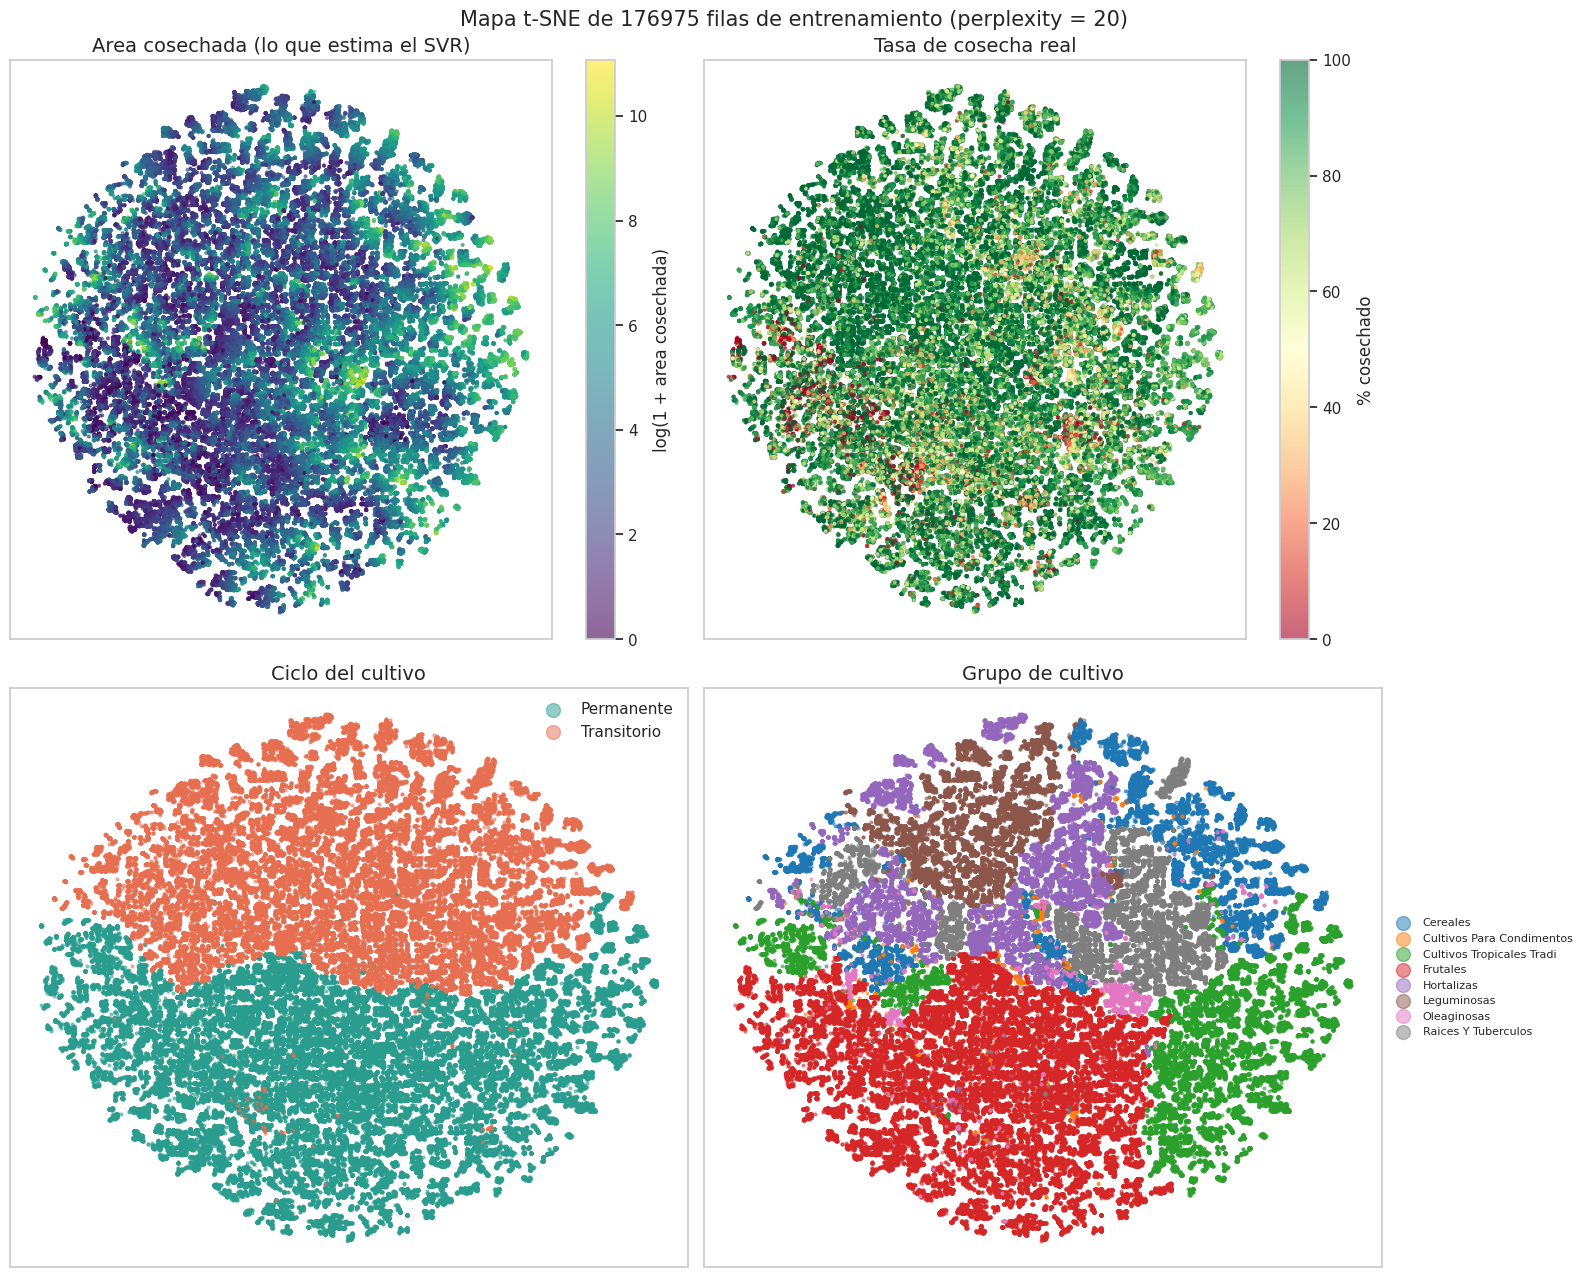

PASO T2: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO T2: Armar el mapa t-SNE y dibujarlo
# =========================================================
print("PASO T2: Armar el mapa t-SNE")
from sklearn.manifold import TSNE

if "mapas" not in globals():
    mapas = {}             # un mapa por cada perplexity ya calculada

# Muestra fija del entrenamiento (la misma para todas las perplexity, para poder comparar)
if MUESTRA_TSNE is None:
    muestra = ent.copy()                                        # todas las filas de entrenamiento
else:
    muestra = ent.sample(MUESTRA_TSNE, random_state=SEMILLA)    # muestra aleatoria
print("Filas para el mapa:", len(muestra))

# Preparacion (147 columnas) -> PCA (50) -> t-SNE (2)
preparacion_mapa = crear_preparacion()
Z = np.asarray(preparacion_mapa.fit_transform(muestra)).astype(np.float32)
print("Columnas despues de la preparacion:", Z.shape[1], "| por bloque:",
      {nombre: (s.stop - s.start) for nombre, s in preparacion_mapa.output_indices_.items()})
Z = PCA(n_components=min(PCA_PREVIO, Z.shape[1]), random_state=SEMILLA).fit_transform(Z)

inicio = time.time()
tsne = TSNE(n_components=2, perplexity=PERPLEXITY, early_exaggeration=EARLY_EXAGGERATION,
            learning_rate=LEARNING_RATE, max_iter=MAX_ITER, init=INIT, random_state=SEMILLA)
puntos = np.asarray(tsne.fit_transform(np.asarray(Z).astype(np.float32)))
mapas[PERPLEXITY] = puntos
print("Mapa armado con", len(puntos), "filas |", round(time.time() - inicio), "s")

# Dibujo: el mismo mapa con 4 colores distintos
figura, ejes = plt.subplots(2, 2, figsize=(16, 13))

d = ejes[0, 0].scatter(puntos[:, 0], puntos[:, 1], c=objetivo(muestra), cmap="viridis", s=4, alpha=0.6)
figura.colorbar(d, ax=ejes[0, 0], label="log(1 + area cosechada)")
ejes[0, 0].set_title("Area cosechada (lo que estima el SVR)")

d = ejes[0, 1].scatter(puntos[:, 0], puntos[:, 1], c=muestra["tasa_real"].clip(0, 1) * 100,
                       cmap="RdYlGn", s=4, alpha=0.6)
figura.colorbar(d, ax=ejes[0, 1], label="% cosechado")
ejes[0, 1].set_title("Tasa de cosecha real")

for ciclo, color in [("PERMANENTE", VERDE), ("TRANSITORIO", NARANJA)]:
    m = (muestra["ciclo"] == ciclo).values
    ejes[1, 0].scatter(puntos[m, 0], puntos[m, 1], color=color, s=4, alpha=0.5, label=ciclo.title())
ejes[1, 0].legend(frameon=False, markerscale=5)
ejes[1, 0].set_title("Ciclo del cultivo")

paleta = sns.color_palette("tab10", muestra["grupo"].nunique())
for (grupo, t), color in zip(muestra.groupby("grupo"), paleta):
    m = (muestra["grupo"] == grupo).values
    ejes[1, 1].scatter(puntos[m, 0], puntos[m, 1], color=color, s=4, alpha=0.5, label=grupo.title()[:25])
ejes[1, 1].legend(frameon=False, markerscale=5, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
ejes[1, 1].set_title("Grupo de cultivo")

for ax in ejes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Mapa t-SNE de " + str(len(muestra)) + " filas de entrenamiento (perplexity = " + str(PERPLEXITY) + ")", fontsize=15)
plt.tight_layout()
plt.show()
print("PASO T2: Ejecutado correctamente")
print("-------------------------------")

PASO T3: Comparar los mapas de distintas perplexity


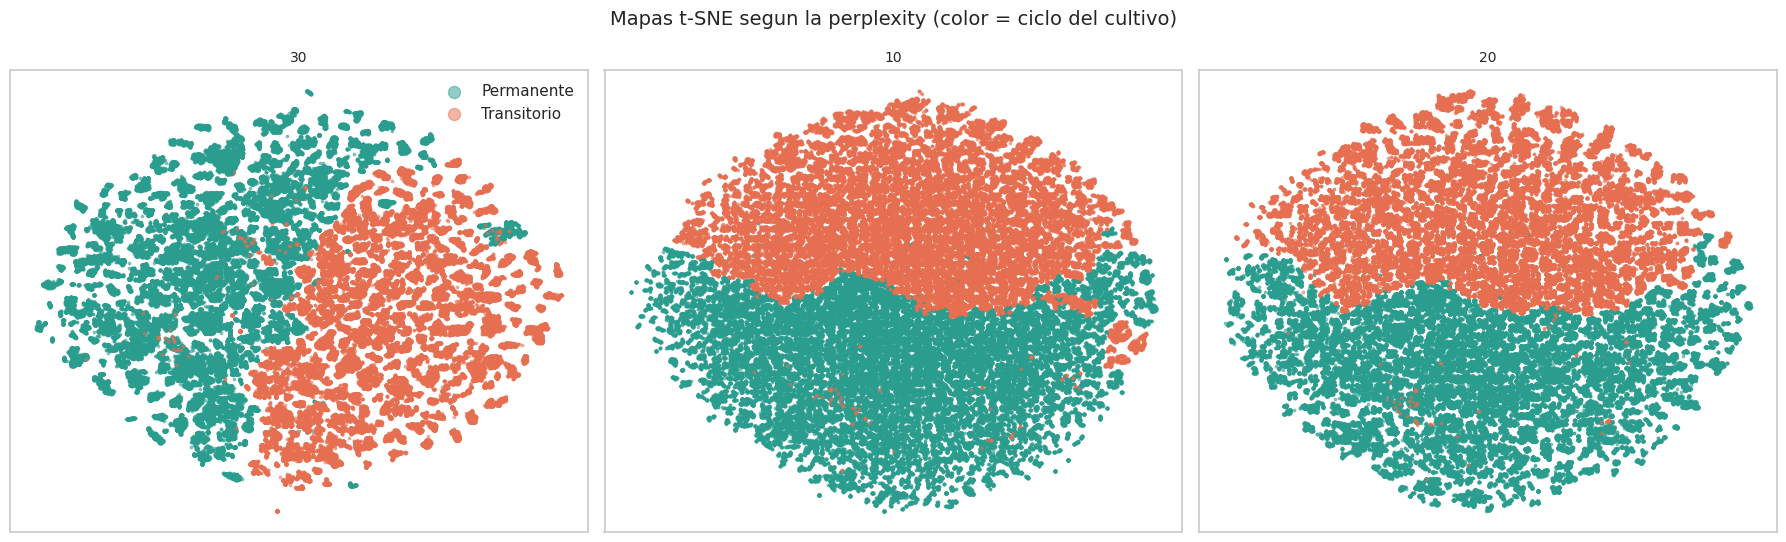

Perplexity probadas: [30, 10, 20]
PASO T3: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO T3: Comparar los mapas de distintas perplexity
# =========================================================
print("PASO T3: Comparar los mapas de distintas perplexity")
hechas = list(mapas)[-3:]          # los ultimos 3 mapas hechos
figura, ejes = plt.subplots(1, len(hechas), figsize=(6 * len(hechas), 5.5), squeeze=False)
for ax, p in zip(ejes[0], hechas):
    for ciclo, color in [("PERMANENTE", VERDE), ("TRANSITORIO", NARANJA)]:
        m = (muestra["ciclo"] == ciclo).values
        ax.scatter(mapas[p][m, 0], mapas[p][m, 1], color=color, s=3, alpha=0.5, label=ciclo.title())
    ax.set_title(p, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
ejes[0][0].legend(frameon=False, markerscale=5)
plt.suptitle("Mapas t-SNE segun la perplexity (color = ciclo del cultivo)", fontsize=14)
plt.tight_layout()
plt.show()
print("Perplexity probadas:", hechas)
print("PASO T3: Ejecutado correctamente")
print("-------------------------------")

## Fase D — Modelos finales y prueba (2023–2025)

Escribir en **D1** los parámetros de PCA elegidos en la fase B. El SVR normal y el SVR con PCA se **reentrenan con 2007–2022** (la preparación y el PCA se vuelven a ajustar con esos años) y se evalúan **una sola vez** en la prueba. El SVR corre en la GPU.

Se guardan en `EVA/Resultados_reduccion/`: `comparacion_reduccion.csv` (la tabla) y `predicciones_SVR_PCA.csv` (mismo formato de `predicciones_SVR.csv`).

In [ ]:
# =========================================================
# PASO D1: Parametros finales  (EDITAR AQUI)
# =========================================================
print("PASO D1: Parametros finales")

N_COMPONENTES_FINAL = 86
GAMMA_PCA_FINAL = 0.01

print("PCA -> n_componentes =", N_COMPONENTES_FINAL, "| gamma =", GAMMA_PCA_FINAL)
print("PASO D1: Ejecutado correctamente")
print("-------------------------------")

PASO D1: Parametros finales
PCA -> n_componentes = 86 | gamma = 0.01
PASO D1: Ejecutado correctamente
-------------------------------


PASO D2: Modelos finales y prueba
SVR normal listo | 65 s
SVR + PCA listo | 58 s

                            Columnas del SVR                    Parametros WAPE validacion 2022 WAPE prueba 2023-2025 WAPE 2023 WAPE 2024 WAPE 2025 R2 prueba Segundos
SVR normal                               147                    gamma=0.01                7.196                 8.128     7.184     9.241     7.999     0.966       65
SVR + PCA                                 86  n_componentes=86, gamma=0.01                7.360                 8.042     7.163     9.172     7.833     0.970       58
Regla: cosechada = sembrada              NaN                             -                9.993                11.997    10.864    13.311    11.862     0.945      NaN


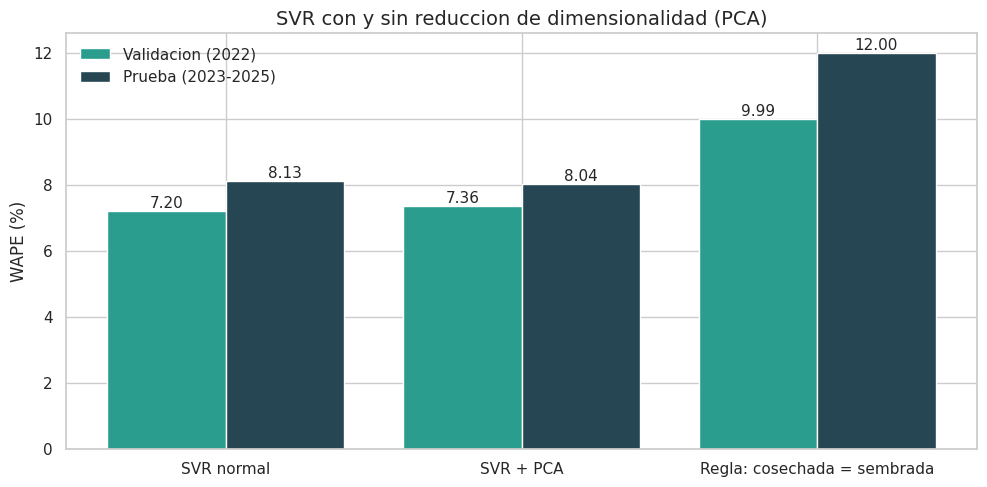

Guardados en /content/drive/MyDrive/EVA/Resultados_reduccion/ : comparacion_reduccion.csv y predicciones_SVR_PCA.csv
PASO D2: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO D2: Modelos finales (2007-2022) y prueba (2023-2025)
# =========================================================
print("PASO D2: Modelos finales y prueba")

# Entrenamiento final con 2007-2022 (el anio se topa en 2022)
entreno_final = df[df["anio"] <= ANIO_VALIDACION].copy()
ent_final = preparar(entreno_final, entreno_final, ANIO_VALIDACION)
prb = preparar(entreno_final, prueba, ANIO_VALIDACION)
real = prb["area_cosechada"].values
estimadas, tiempos = {}, {}

# --- Version 1: SVR normal ---
inicio = time.time()
m = Pipeline([("preparacion", crear_preparacion()), ("float32", a_float32()), ("svr", crear_svr(GAMMA_NORMAL))])
m.fit(ent_final, objetivo(ent_final))
estimadas["SVR normal"] = a_hectareas(m.predict(prb), prb)
tiempos["SVR normal"] = round(time.time() - inicio)
print("SVR normal listo |", tiempos["SVR normal"], "s")

# --- Version 2: SVR con PCA ---
inicio = time.time()
m = crear_modelo_pca(N_COMPONENTES_FINAL, GAMMA_PCA_FINAL)
m.fit(ent_final, objetivo(ent_final))
estimadas["SVR + PCA"] = a_hectareas(m.predict(prb), prb)
tiempos["SVR + PCA"] = round(time.time() - inicio)
print("SVR + PCA listo |", tiempos["SVR + PCA"], "s")

estimadas["Regla: cosechada = sembrada"] = prb["area_sembrada"].values.astype(float)

# --- WAPE de validacion de la corrida de PCA elegida (del registro de la fase B) ---
t = registro[(registro["version"] == "PCA")
             & np.isclose(registro["parametro"].astype(float), N_COMPONENTES_FINAL)
             & np.isclose(registro["gamma"].astype(float), GAMMA_PCA_FINAL)]
wape_val_pca = t["WAPE_validacion"].iloc[-1] if len(t) > 0 else np.nan

detalles = {
    "SVR normal": (N_COLUMNAS, "gamma=" + txt(GAMMA_NORMAL), WAPE_NORMAL_VAL),
    "SVR + PCA": (N_COMPONENTES_FINAL, "n_componentes=" + str(N_COMPONENTES_FINAL) + ", gamma=" + txt(GAMMA_PCA_FINAL), wape_val_pca),
    "Regla: cosechada = sembrada": (np.nan, "-", WAPE_REGLA_VAL),
}

# --- Tabla de comparacion ---
filas = {}
for nombre, estimada in estimadas.items():
    fila = {"Columnas del SVR": detalles[nombre][0], "Parametros": detalles[nombre][1],
            "WAPE validacion 2022": detalles[nombre][2], "WAPE prueba 2023-2025": wape(real, estimada)}
    for anio in ANIOS_PRUEBA:
        del_anio = (prb["anio"] == anio).values
        fila["WAPE " + str(anio)] = wape(real[del_anio], estimada[del_anio])
    fila["R2 prueba"] = r2_score(real, estimada)
    fila["Segundos"] = tiempos.get(nombre, np.nan)
    filas[nombre] = fila
comparacion = pd.DataFrame(filas).T
print()
print(comparacion.to_string())

# --- Grafica: WAPE en validacion y en prueba de cada version ---
x = np.arange(len(comparacion))
plt.figure(figsize=(10, 5))
b1 = plt.bar(x - 0.2, comparacion["WAPE validacion 2022"].astype(float), 0.4, color=VERDE, label="Validacion (2022)")
b2 = plt.bar(x + 0.2, comparacion["WAPE prueba 2023-2025"].astype(float), 0.4, color=AZUL, label="Prueba (2023-2025)")
plt.bar_label(b1, fmt="%.2f")
plt.bar_label(b2, fmt="%.2f")
plt.xticks(x, comparacion.index)
plt.ylabel("WAPE (%)")
plt.title("SVR con y sin reduccion de dimensionalidad (PCA)")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

# --- Archivos ---
comparacion.to_csv(RUTA_REDUCCION + "comparacion_reduccion.csv", encoding="utf-8-sig")
tabla_predicciones(prb, estimadas["SVR + PCA"], "SVR + PCA").to_csv(
    RUTA_REDUCCION + "predicciones_SVR_PCA.csv", index=False, encoding="utf-8-sig")
print("Guardados en", RUTA_REDUCCION, ": comparacion_reduccion.csv y predicciones_SVR_PCA.csv")
print("PASO D2: Ejecutado correctamente")
print("-------------------------------")